# 05 - Modelos clásicos sobre los embeddings
**Proyecto 2 - CGIAR Eyes on the Ground**

Este notebook corre en la laptop, sin GPU. Entrena regresión logística, SVM y Random Forest sobre los embeddings de ResNet50 y EfficientNet-B0 (notebook 04), usando la partición del notebook 02. Sirve para comparar algoritmos y para tener una referencia contra la cual medir el fine-tuning de las CNN (notebook 06).

Para repetir el experimento con las 8 clases originales basta con cambiar `OBJETIVO` a `"damage"`.

## 1. Cómo se evalúa

- **Entrenamiento:** solo con las fotos de `train`.
- **Selección de parámetros:** se prueban unos pocos valores por modelo y se elige el de mayor F1 macro en `val`.
- **Test:** se usa una sola vez, al final, con el mejor modelo de cada tipo. Así la comparación no se contamina con decisiones tomadas viendo el test.
- **Desbalance:** los tres modelos usan `class_weight="balanced"`, que le da más peso a las clases con pocas fotos.
- **Métrica principal:** F1 macro, que promedia el F1 de cada clase sin que dominen las más grandes. También se reportan balanced accuracy, accuracy y el F1 por clase.
- **Referencias:** un clasificador que siempre responde la clase más común y uno que responde al azar según la proporción de clases.
- **SVM:** el kernel RBF escala mal con 2048 dimensiones, así que antes del SVM se reduce con PCA a 256.

In [22]:
import sys
import time
import warnings
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

RAIZ = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
sys.path.append(str(RAIZ))

from src.modelos_clasicos import GRILLAS, crear_pipeline, crear_baseline, evaluar

sns.set_theme(style="whitegrid")
warnings.filterwarnings("ignore", category=UserWarning)

# ---------- Ajustar ----------
OBJETIVO = "clase4"     # "clase4" (experimento principal) o "damage" (8 clases)
MUESTRA = None          # número de fotos de train para una prueba rápida (por ejemplo 3000)
SEMILLA = 42
EMBEDDINGS = ["resnet50", "efficientnet_b0"]
# -----------------------------

SUFIJO = OBJETIVO + ("_prueba" if MUESTRA else "")

## 2. Datos

In [23]:
NOMBRES_DANO = {"DR": "Sequía", "DS": "Enfermedad", "FD": "Inundación", "G": "Bueno",
                "ND": "Deficiencia de nutrientes", "PS": "Plaga", "WD": "Maleza", "WN": "Viento"}

DIR_EMB = RAIZ / "data" / "embeddings"
indice = pd.read_csv(DIR_EMB / "indice.csv")
X_todo = {nombre: np.load(DIR_EMB / f"{nombre}.npy") for nombre in EMBEDDINGS}

if OBJETIVO == "damage":
    y = indice["damage"].map(NOMBRES_DANO).values
else:
    y = indice[OBJETIVO].values

es_train = (indice["split"] == "train").values
es_val = (indice["split"] == "val").values
es_test = (indice["split"] == "test").values

if MUESTRA:
    rng = np.random.default_rng(SEMILLA)
    pos = np.flatnonzero(es_train)
    es_train = np.zeros(len(indice), dtype=bool)
    es_train[rng.choice(pos, size=MUESTRA, replace=False)] = True

for nombre, X in X_todo.items():
    assert len(X) == len(indice), f"{nombre}: el número de filas no coincide con indice.csv"

print({nombre: X.shape for nombre, X in X_todo.items()})
pd.crosstab(pd.Series(y, name=OBJETIVO), indice["split"])[["train", "val", "test"]]

{'resnet50': (26068, 2048), 'efficientnet_b0': (26068, 1280)}


split,train,val,test
clase4,,,
Bueno,8302,1661,1660
Maleza,6600,1319,1319
Otro daño,492,99,100
Sequía,3226,645,645


## 3. Búsqueda de parámetros

Cada combinación se entrena con `train` y se mide en `val`. De cada tipo de modelo solo se guarda el mejor, para no llenar la memoria con todos los Random Forest.

In [24]:
registro = []
mejores = {}   # (embedding, modelo) -> (f1_val, pipeline, parametros, tiempo_entrenamiento)

for emb, X in X_todo.items():
    for modelo, grilla in GRILLAS.items():
        for params in grilla:
            pipe = crear_pipeline(modelo, semilla=SEMILLA, **params)

            t0 = time.time()
            pipe.fit(X[es_train], y[es_train])
            t_fit = time.time() - t0

            m = evaluar(pipe, X[es_val], y[es_val])
            registro.append({"embedding": emb, "modelo": modelo, "parametros": str(params),
                             "f1_macro_val": m["f1_macro"], "tiempo_entrenamiento_s": t_fit})
            print(f"{emb:16s} {modelo:20s} {str(params):26s} F1 macro val = {m['f1_macro']:.3f}  ({t_fit:.0f} s)")

            clave = (emb, modelo)
            if clave not in mejores or m["f1_macro"] > mejores[clave][0]:
                mejores[clave] = (m["f1_macro"], pipe, params, t_fit)

resnet50         regresion_logistica  {'C': 0.0003}              F1 macro val = 0.485  (3 s)
resnet50         regresion_logistica  {'C': 0.001}               F1 macro val = 0.484  (4 s)
resnet50         regresion_logistica  {'C': 0.01}                F1 macro val = 0.473  (14 s)
resnet50         regresion_logistica  {'C': 0.1}                 F1 macro val = 0.462  (8 s)
resnet50         svm                  {'C': 1.0}                 F1 macro val = 0.483  (48 s)
resnet50         svm                  {'C': 10.0}                F1 macro val = 0.480  (84 s)
resnet50         svm                  {'C': 30.0}                F1 macro val = 0.471  (120 s)
resnet50         random_forest        {'min_samples_leaf': 1}    F1 macro val = 0.462  (5 s)
resnet50         random_forest        {'min_samples_leaf': 3}    F1 macro val = 0.463  (5 s)
efficientnet_b0  regresion_logistica  {'C': 0.0003}              F1 macro val = 0.506  (4 s)
efficientnet_b0  regresion_logistica  {'C': 0.001}               

In [25]:
busqueda = pd.DataFrame(registro)
busqueda.round(3)

,embedding,modelo,parametros,f1_macro_val,tiempo_entrenamiento_s
0,resnet50,regresion_logistica,{'C': 0.0003},0.485,3.204
1,resnet50,regresion_logistica,{'C': 0.001},0.484,4.010
2,resnet50,regresion_logistica,{'C': 0.01},0.473,13.576
3,resnet50,regresion_logistica,{'C': 0.1},0.462,7.619
4,resnet50,svm,{'C': 1.0},0.483,47.882
5,resnet50,svm,{'C': 10.0},0.480,84.336
6,resnet50,svm,{'C': 30.0},0.471,120.120
7,resnet50,random_forest,{'min_samples_leaf': 1},0.462,5.246
8,resnet50,random_forest,{'min_samples_leaf': 3},0.463,4.998
9,efficientnet_b0,regresion_logistica,{'C': 0.0003},0.506,3.901


## 4. Evaluación en test

In [26]:
filas = []
pred_test = {}

for (emb, modelo), (f1_val, pipe, params, t_fit) in mejores.items():
    m = evaluar(pipe, X_todo[emb][es_test], y[es_test])
    pred_test[(emb, modelo)] = m["pred"]
    fila = {"embedding": emb, "modelo": modelo, "parametros": str(params),
            "f1_macro_val": f1_val, "f1_macro_test": m["f1_macro"],
            "balanced_accuracy_test": m["balanced_accuracy"], "accuracy_test": m["accuracy"],
            "tiempo_entrenamiento_s": t_fit, "tiempo_prediccion_s": m["tiempo_prediccion_s"]}
    fila.update({f"f1_{clase}": v for clase, v in m["f1_por_clase"].items()})
    filas.append(fila)

# Referencias
baselines = {}
for estrategia in ["most_frequent", "stratified"]:
    base = crear_baseline(estrategia, SEMILLA).fit(X_todo[EMBEDDINGS[0]][es_train], y[es_train])
    mb = evaluar(base, X_todo[EMBEDDINGS[0]][es_test], y[es_test])
    baselines[estrategia] = mb
    fila = {"embedding": "-", "modelo": f"baseline_{estrategia}", "parametros": "",
            "f1_macro_test": mb["f1_macro"], "balanced_accuracy_test": mb["balanced_accuracy"],
            "accuracy_test": mb["accuracy"]}
    fila.update({f"f1_{clase}": v for clase, v in mb["f1_por_clase"].items()})
    filas.append(fila)

resultados = pd.DataFrame(filas)
columnas_f1 = [c for c in resultados.columns if c.startswith("f1_") and c not in ("f1_macro_val", "f1_macro_test")]
resultados = resultados[["embedding", "modelo", "parametros", "f1_macro_val", "f1_macro_test",
                         "balanced_accuracy_test", "accuracy_test", *columnas_f1,
                         "tiempo_entrenamiento_s", "tiempo_prediccion_s"]]
resultados.sort_values("f1_macro_test", ascending=False).round(3)

,embedding,modelo,parametros,f1_macro_val,f1_macro_test,balanced_accuracy_test,accuracy_test,f1_Bueno,f1_Maleza,f1_Otro daño,f1_Sequía,tiempo_entrenamiento_s,tiempo_prediccion_s
4,efficientnet_b0,svm,{'C': 10.0},0.535,0.546,0.536,0.664,0.696,0.652,0.180,0.655,84.545,8.746
3,efficientnet_b0,regresion_logistica,{'C': 0.001},0.510,0.534,0.600,0.622,0.651,0.668,0.173,0.646,2.812,0.011
5,efficientnet_b0,random_forest,{'min_samples_leaf': 3},0.492,0.522,0.519,0.637,0.658,0.628,0.155,0.649,8.077,0.060
2,resnet50,random_forest,{'min_samples_leaf': 3},0.463,0.509,0.510,0.618,0.636,0.600,0.150,0.649,4.998,0.073
1,resnet50,svm,{'C': 1.0},0.483,0.501,0.536,0.589,0.621,0.589,0.160,0.633,47.882,9.222
0,resnet50,regresion_logistica,{'C': 0.0003},0.485,0.500,0.552,0.585,0.606,0.625,0.138,0.630,3.204,0.025
7,-,baseline_stratified,,NaN,0.250,0.250,0.355,0.443,0.355,0.020,0.183,NaN,NaN
6,-,baseline_most_frequent,,NaN,0.154,0.250,0.446,0.617,0.000,0.000,0.000,NaN,NaN


## 5. Gráficos para el informe

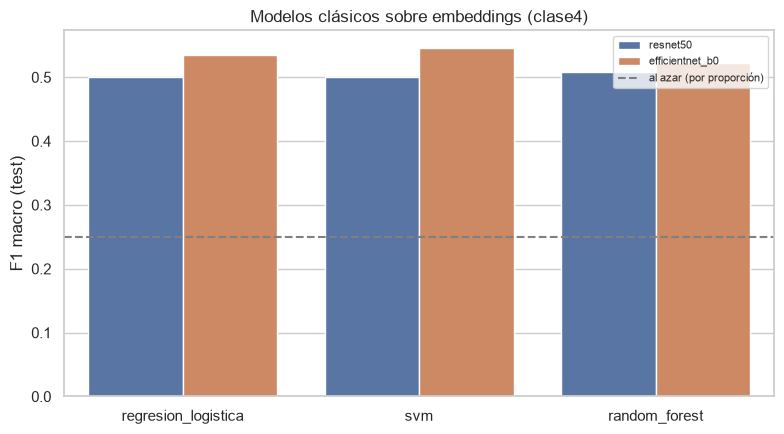

In [27]:
# F1 macro en test por modelo y embedding
reales = resultados[resultados["embedding"] != "-"]

fig, ax = plt.subplots(figsize=(8, 4.5))
sns.barplot(data=reales, x="modelo", y="f1_macro_test", hue="embedding", ax=ax)
ax.axhline(baselines["stratified"]["f1_macro"], color="gray", linestyle="--", label="al azar (por proporción)")
ax.set_ylabel("F1 macro (test)")
ax.set_xlabel("")
ax.set_title(f"Modelos clásicos sobre embeddings ({OBJETIVO})")
ax.legend(loc="best", fontsize=8)
fig.tight_layout()
(RAIZ / "figuras").mkdir(exist_ok=True)
fig.savefig(RAIZ / "figuras" / f"clasicos_{SUFIJO}_f1_macro.png", dpi=150, bbox_inches="tight")
plt.show()

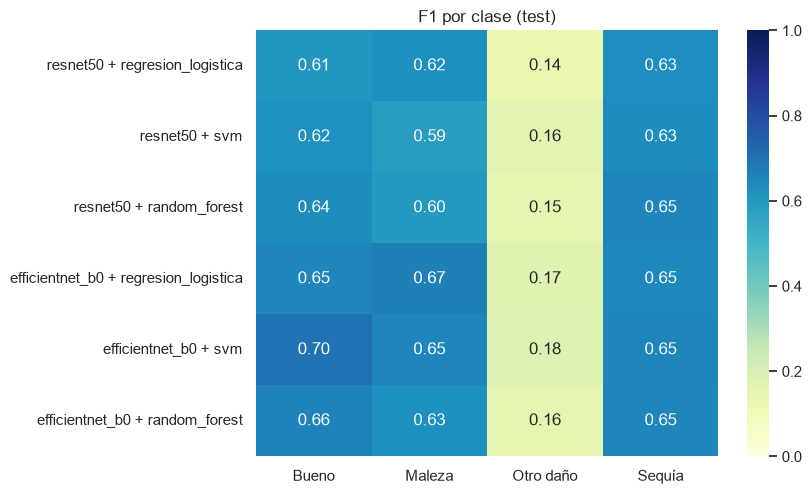

In [28]:
# F1 por clase
fila_id = reales["embedding"] + " + " + reales["modelo"]
tabla = reales[columnas_f1].copy()
tabla.index = fila_id
tabla.columns = [c.replace("f1_", "") for c in tabla.columns]

fig, ax = plt.subplots(figsize=(1.4 * len(tabla.columns) + 3, 0.6 * len(tabla) + 1.5))
sns.heatmap(tabla.astype(float), annot=True, fmt=".2f", cmap="YlGnBu", vmin=0, vmax=1, ax=ax)
ax.set_title("F1 por clase (test)")
fig.tight_layout()
fig.savefig(RAIZ / "figuras" / f"clasicos_{SUFIJO}_f1_por_clase.png", dpi=150, bbox_inches="tight")
plt.show()

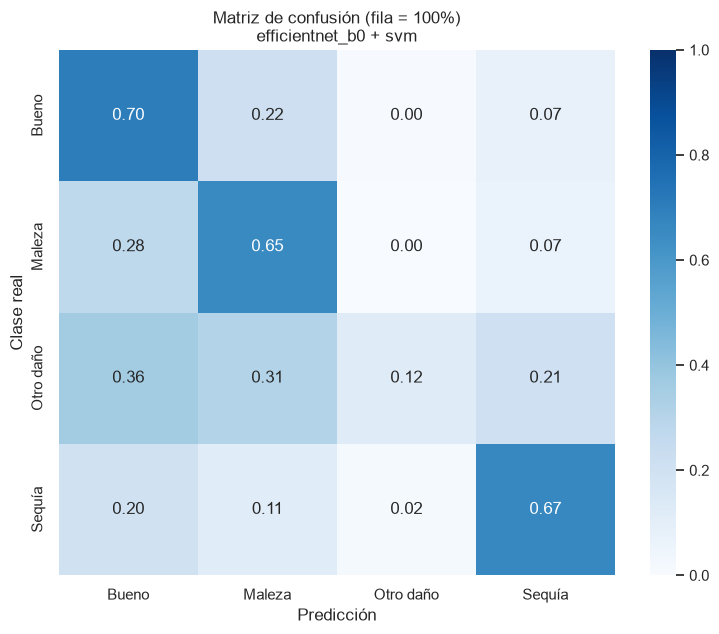

In [29]:
# Matriz de confusión del mejor modelo (elegido por F1 macro en validación, no en test)
emb_mejor, modelo_mejor = max(mejores, key=lambda k: mejores[k][0])
clases = sorted(set(y))
cm = confusion_matrix(y[es_test], pred_test[(emb_mejor, modelo_mejor)], labels=clases, normalize="true")

fig, ax = plt.subplots(figsize=(1.2 * len(clases) + 3, 1.0 * len(clases) + 2.5))
sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues", xticklabels=clases, yticklabels=clases, vmin=0, vmax=1, ax=ax)
ax.set_xlabel("Predicción")
ax.set_ylabel("Clase real")
ax.set_title(f"Matriz de confusión (fila = 100%)\n{emb_mejor} + {modelo_mejor}")
fig.tight_layout()
fig.savefig(RAIZ / "figuras" / f"clasicos_{SUFIJO}_confusion.png", dpi=150, bbox_inches="tight")
plt.show()

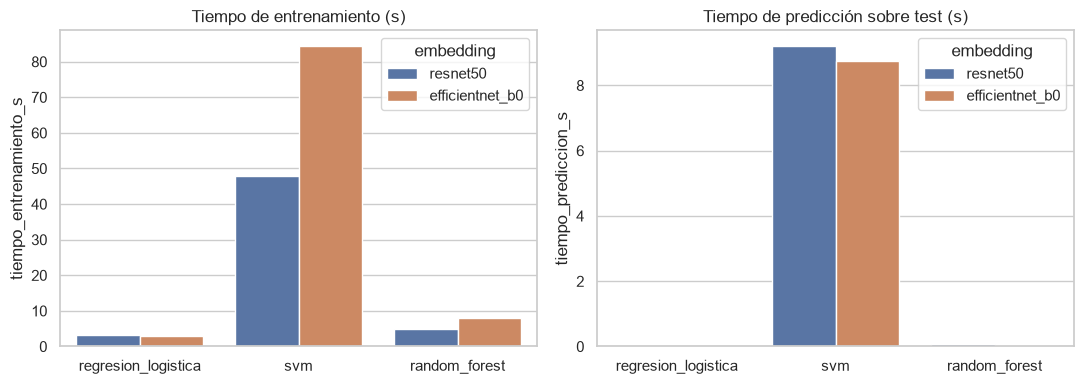

In [30]:
# Tiempos
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.barplot(data=reales, x="modelo", y="tiempo_entrenamiento_s", hue="embedding", ax=axes[0])
axes[0].set_title("Tiempo de entrenamiento (s)")
sns.barplot(data=reales, x="modelo", y="tiempo_prediccion_s", hue="embedding", ax=axes[1])
axes[1].set_title("Tiempo de predicción sobre test (s)")
for ax in axes:
    ax.set_xlabel("")
fig.tight_layout()
fig.savefig(RAIZ / "figuras" / f"clasicos_{SUFIJO}_tiempos.png", dpi=150, bbox_inches="tight")
plt.show()

## 6. Guardar resultados y modelos

In [31]:
(RAIZ / "resultados").mkdir(exist_ok=True)
resultados.to_csv(RAIZ / "resultados" / f"clasicos_{SUFIJO}.csv", index=False)
busqueda.to_csv(RAIZ / "resultados" / f"clasicos_{SUFIJO}_busqueda.csv", index=False)

(RAIZ / "models").mkdir(exist_ok=True)
for (emb, modelo), (f1_val, pipe, params, t_fit) in mejores.items():
    ruta = RAIZ / "models" / f"{emb}_{modelo}_{SUFIJO}.joblib"
    joblib.dump(pipe, ruta, compress=3)
    print(f"{ruta.name}: {ruta.stat().st_size / 1e6:.0f} MB")

resnet50_regresion_logistica_clase4.joblib: 0 MB
resnet50_svm_clase4.joblib: 21 MB
resnet50_random_forest_clase4.joblib: 16 MB
efficientnet_b0_regresion_logistica_clase4.joblib: 0 MB
efficientnet_b0_svm_clase4.joblib: 20 MB
efficientnet_b0_random_forest_clase4.joblib: 15 MB


## Siguiente paso

Si estos modelos quedan por debajo de lo esperado, es una señal de que los embeddings congelados de ImageNet no capturan bien la diferencia entre clases en estas fotos. El notebook 06 entrena las CNN completas (fine-tuning) para ver cuánto mejora.